# Exercise 1 — Introduction to Speech Recognition

This notebook implements **both questions** of the assignment. It follows the DFT and Hamming-window definitions from Lecture 2 and the multivariate Gaussian formulation from Lecture 3.

- **Question 1 (a–g):** three-tone signals, an explicitly constructed DFT matrix, spectral leakage, and the Hamming window.
- **Question 2 (a–e):** diagonal/full Gaussian density models, estimated parameters, log-likelihood tables, and a comparison of the datasets.

**Run all cells in order.** The four input CSV files are expected to be in the **same directory as this notebook**. No external datasets or random numbers are used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

np.set_printoptions(precision=6, suppress=True)

## Question 1 — Discrete Fourier Transform

We generate $N=400$ samples at $f_s=16{,}000\,\mathrm{Hz}$ (duration $N/f_s=25\,\mathrm{ms}$):

$$
s[n]=\sum_{j=1}^{3} A_j\cos\!\left(2\pi f_j \frac{n}{f_s}+\phi_j\right),
\qquad n=0,\ldots,N-1.
$$

The amplitudes are $(0.4,0.3,0.25)$ and the phases are $(\pi/4,0,-3\pi/4)$. The two signals differ **only** in their frequencies:

| Tone | Amplitude | Phase (rad) | $s_1$ frequency (Hz) | $s_2$ frequency (Hz) |
|:--:|--:|--:|--:|--:|
| 1 | 0.40 | $\pi/4$ | 440 | 450 |
| 2 | 0.30 | $0$ | 1200 | 1100 |
| 3 | 0.25 | $-3\pi/4$ | 2600 | 2550 |

In [2]:
SAMPLE_RATE = 16_000
N = 400
AMPLITUDES = np.array([0.4, 0.3, 0.25])
PHASES = np.array([np.pi / 4, 0, -3 * np.pi / 4])
FREQUENCIES_1 = np.array([440, 1200, 2600])
FREQUENCIES_2 = np.array([450, 1100, 2550])
BIN_WIDTH = SAMPLE_RATE / N  # 40 Hz


def make_signal(frequencies):
    time = np.arange(N) / SAMPLE_RATE
    angles = 2 * np.pi * frequencies[:, None] * time + PHASES[:, None]
    return np.sum(AMPLITUDES[:, None] * np.cos(angles), axis=0)


signal_1 = make_signal(FREQUENCIES_1)
signal_2 = make_signal(FREQUENCIES_2)
print(f"Signal length: {N} samples = {N / SAMPLE_RATE:.3f} s")
print(f"DFT frequency resolution: {BIN_WIDTH:.0f} Hz per bin")

Signal length: 400 samples = 0.025 s
DFT frequency resolution: 40 Hz per bin


### (a–b) Construct the DFT matrix and plot $s_1$

From Lecture 2, the DFT is $X=Ws$, with matrix elements

$$W_{k,n}=e^{-i2\pi kn/N}, \qquad 0\le k,n<N.$$

We construct this matrix **ourselves** and multiply it by the signal. We do **not** call an FFT/DFT library function.

Because the samples are real, $X[N-k]=\overline{X[k]}$ (conjugate symmetry). The negative-frequency half therefore carries no additional information. As requested, the plots show **bins $0$ through $199$**. The Nyquist bin $k=200$ is a special real-valued bin, not relevant to these tones.

For readability, the magnitude is displayed on a relative dB scale: $20\log_{10}(|X[k]|/\max|X_1|)$, with a plotting floor of $-80\,\mathrm{dB}$.

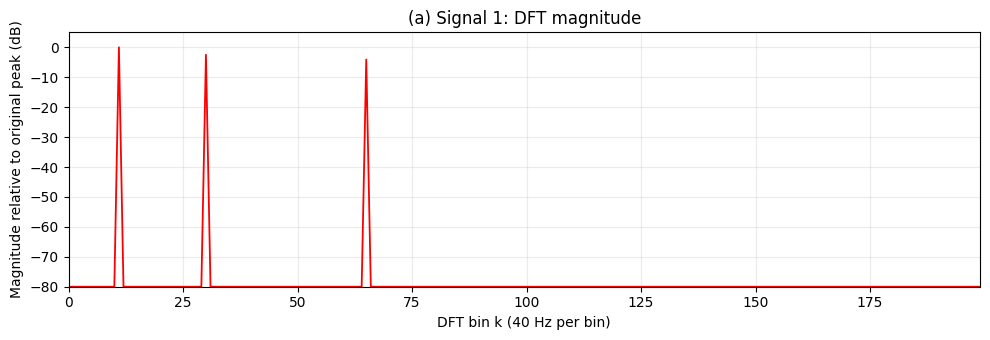

In [3]:
def dft_matrix(size):
    indices = np.arange(size)
    return np.exp(-2j * np.pi * np.outer(indices, indices) / size)


def plot_spectrum(original, title, windowed=None):
    bins = np.arange(N // 2)
    peak = np.max(np.abs(original[: N // 2]))

    def db(values):
        magnitudes = np.abs(values[: N // 2]) / peak
        return 20 * np.log10(np.maximum(magnitudes, 1e-4))

    plt.figure(figsize=(10, 3.5))
    plt.plot(bins, db(original), color="red", linewidth=1.3, label="Original")
    if windowed is not None:
        plt.plot(bins, db(windowed), color="green", linewidth=1.3, label="Hamming window")
        plt.legend()
    plt.title(title)
    plt.xlabel("DFT bin k (40 Hz per bin)")
    plt.ylabel("Magnitude relative to original peak (dB)")
    plt.xlim(0, N // 2 - 1)
    plt.ylim(-80, 5)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


W = dft_matrix(N)
X1 = W @ signal_1
plot_spectrum(X1, "(a) Signal 1: DFT magnitude")

### (c) Read amplitude and phase from $s_1$ coefficients

Each DFT bin represents $f_k=k f_s/N=40k\,\mathrm{Hz}$. For a cosine that falls exactly on a positive-frequency bin, its coefficient is

$$X[k]=\frac{N A}{2}e^{i\phi}, \qquad
A=\frac{2|X[k]|}{N},\quad \phi=\arg X[k].$$

This conversion assumes an *isolated*, bin-aligned tone. All three frequencies in $s_1$ are exact multiples of $40\,\mathrm{Hz}$, so their coefficients reproduce the original amplitudes and phases (up to numerical precision).

In [4]:
def nearest_bins(frequency):
    position = frequency / BIN_WIDTH
    lower, upper = int(np.floor(position)), int(np.ceil(position))
    if lower != upper and np.isclose(position - lower, 0.5):
        return [lower, upper]  # Exactly halfway between two DFT bins
    return [int(np.floor(position + 0.5))]


def show_tone_estimates(frequencies, spectrum, title, gain=None):
    rows = []
    for frequency in frequencies:
        for k in nearest_bins(frequency):
            amplitude = 2 * np.abs(spectrum[k]) / N
            phase = np.angle(spectrum[k])
            corrected = f"{amplitude / gain:.5f}" if gain is not None else "—"
            rows.append(
                f"| {frequency} | {k} | {k * BIN_WIDTH:.0f} | "
                f"{amplitude:.5f} | {phase:.5f} | {corrected} |"
            )

    display(Markdown(
        f"**{title}**\n\n"
        "| Tone (Hz) | Bin $k$ | Bin frequency (Hz) | $2|X[k]|/N$ | Phase (rad) | Gain-corrected amplitude |\n"
        "|---:|---:|---:|---:|---:|---:|\n" + "\n".join(rows)
    ))


show_tone_estimates(FREQUENCIES_1, X1, "(c) Signal 1, unwindowed")

**(c) Signal 1, unwindowed**

| Tone (Hz) | Bin $k$ | Bin frequency (Hz) | $2|X[k]|/N$ | Phase (rad) | Gain-corrected amplitude |
|---:|---:|---:|---:|---:|---:|
| 440 | 11 | 440 | 0.40000 | 0.78540 | — |
| 1200 | 30 | 1200 | 0.30000 | -0.00000 | — |
| 2600 | 65 | 2600 | 0.25000 | -2.35619 | — |

### (d–e) DFT of $s_2$: tones between bins

For $s_2$, the bin positions are $450/40=11.25$, $1100/40=27.5$, and $2550/40=63.75$. None is an integer.

The finite-length DFT therefore exhibits **spectral leakage**: energy spreads into many bins instead of appearing at a single bin. We report the nearest bin for tones 1 and 3, and **both equally near bins** for the 1100 Hz tone. The resulting amplitudes and phases are *estimates obtained from those bins*, not exact recoveries of the original sinusoid parameters.

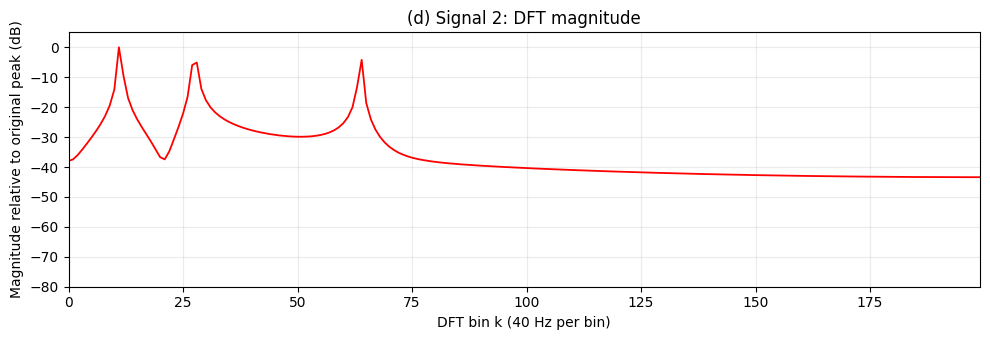

**(e) Signal 2, unwindowed**

| Tone (Hz) | Bin $k$ | Bin frequency (Hz) | $2|X[k]|/N$ | Phase (rad) | Gain-corrected amplitude |
|---:|---:|---:|---:|---:|---:|
| 450 | 11 | 440 | 0.35950 | 1.55805 | — |
| 1100 | 27 | 1080 | 0.18144 | 1.54371 | — |
| 1100 | 28 | 1120 | 0.20022 | -1.54607 | — |
| 2550 | 64 | 2560 | 0.22197 | -3.11427 | — |

In [5]:
X2 = W @ signal_2
plot_spectrum(X2, "(d) Signal 2: DFT magnitude")
show_tone_estimates(FREQUENCIES_2, X2, "(e) Signal 2, unwindowed")

### (f) Apply the Hamming window and compare spectra

**Important:** Lecture 2 defines the *periodic* Hamming window as

$$w[n]=\frac{25}{54}-\frac{21}{54}\cos\!\left(\frac{2\pi n}{N}\right),\qquad n=0,\ldots,N-1.$$

We use this exact formula (not the symmetric $N-1$ variant used by some libraries).

Multiplication in time corresponds to convolution in frequency. Windowing reduces distant **sidelobes** (leakage) but **widens the main lobe** around each tone. For an exactly bin-aligned tone, energy appears in its bin and the two adjacent bins instead of a single bin. Since the window has mean $25/54$, it also reduces the uncorrected peak magnitude by approximately that factor.

Hamming mean (coherent gain): 0.462963


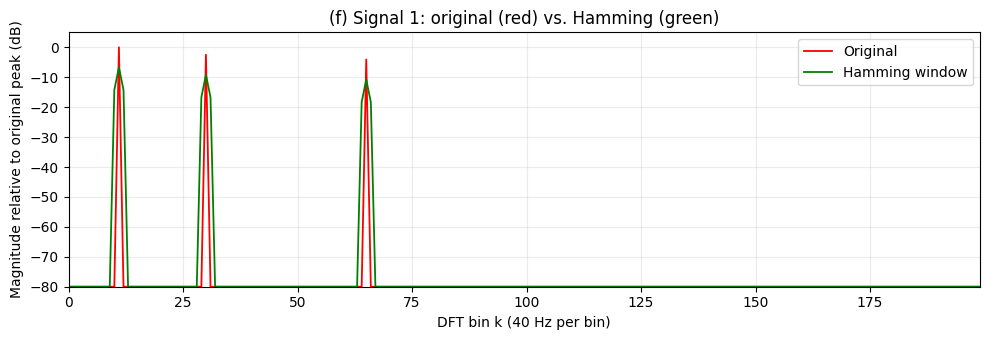

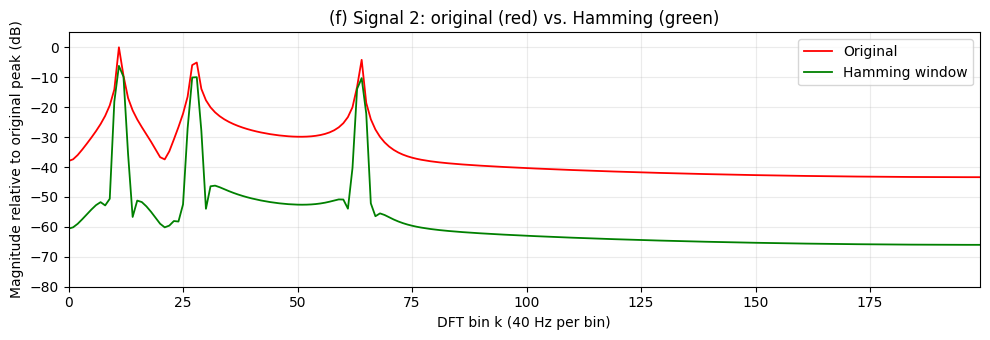

In [6]:
def hamming_window(size):
    n = np.arange(size)
    return 25 / 54 - (21 / 54) * np.cos(2 * np.pi * n / size)


window = hamming_window(N)
window_gain = window.mean()
X1_windowed = W @ (signal_1 * window)
X2_windowed = W @ (signal_2 * window)

print(f"Hamming mean (coherent gain): {window_gain:.6f}")
plot_spectrum(X1, "(f) Signal 1: original (red) vs. Hamming (green)", X1_windowed)
plot_spectrum(X2, "(f) Signal 2: original (red) vs. Hamming (green)", X2_windowed)

### (g) Windowed amplitudes and phases

We again use $2|X[k]|/N$ and $\arg X[k]$ from the selected coefficients. The final table column also divides the amplitude by the **coherent gain**, $\frac{1}{N}\sum_n w[n]=25/54$.

For $s_1$, the original tones align with bins, so gain correction recovers their amplitudes (the phase is essentially unchanged). For $s_2$, leakage and the broadened main lobes mean that even gain-corrected **single-bin** values need not equal the true amplitudes or phases; especially at 1100 Hz, there is no unique nearest bin. Windowing is a leakage-control technique, **not** a guarantee of exact off-grid parameter recovery.

In [7]:
show_tone_estimates(FREQUENCIES_1, X1_windowed, "(g) Signal 1, Hamming window", window_gain)
show_tone_estimates(FREQUENCIES_2, X2_windowed, "(g) Signal 2, Hamming window", window_gain)

**(g) Signal 1, Hamming window**

| Tone (Hz) | Bin $k$ | Bin frequency (Hz) | $2|X[k]|/N$ | Phase (rad) | Gain-corrected amplitude |
|---:|---:|---:|---:|---:|---:|
| 440 | 11 | 440 | 0.18519 | 0.78540 | 0.40000 |
| 1200 | 30 | 1200 | 0.13889 | -0.00000 | 0.30000 |
| 2600 | 65 | 2600 | 0.11574 | -2.35619 | 0.25000 |

**(g) Signal 2, Hamming window**

| Tone (Hz) | Bin $k$ | Bin frequency (Hz) | $2|X[k]|/N$ | Phase (rad) | Gain-corrected amplitude |
|---:|---:|---:|---:|---:|---:|
| 450 | 11 | 440 | 0.17601 | 1.56887 | 0.38018 |
| 1100 | 27 | 1080 | 0.11248 | 1.56756 | 0.24295 |
| 1100 | 28 | 1120 | 0.11385 | -1.56758 | 0.24591 |
| 2550 | 64 | 2560 | 0.10980 | -3.13751 | 0.23717 |

## Question 2 — Multivariate Gaussian models

A $d$-dimensional Gaussian with mean $\mu$ and covariance $\Sigma$ has density

$$p(x)=\frac{1}{(2\pi)^{d/2}\sqrt{\det\Sigma}}
\exp\!\left(-\frac{1}{2}(x-\mu)^T\Sigma^{-1}(x-\mu)\right).$$

Its **log-density** (called `log_likelihood` in the assignment) is

$$\log p(x)=-\frac{d}{2}\log(2\pi)-\frac{1}{2}\log\det\Sigma
-\frac{1}{2}(x-\mu)^T\Sigma^{-1}(x-\mu).$$

For diagonal covariance, the matrix inverse and determinant simplify to elementwise reciprocals and the product of variances. Both implementations precompute the inverse/precision and normalization in `__init__`, so repeated queries only calculate a quadratic form.

In [8]:
class Gaussian:
    """Multivariate Gaussian with a diagonal variance vector or full covariance matrix."""

    def __init__(self, mean, covariance):
        self.mean = np.asarray(mean, dtype=float)
        self.covariance = np.asarray(covariance, dtype=float)
        if self.mean.ndim != 1 or self.mean.size == 0:
            raise ValueError("mean must be a nonempty vector")

        d = self.mean.size
        if self.covariance.shape == (d,):
            if np.any(self.covariance <= 0):
                raise ValueError("variances must be positive")
            self.diagonal = True
            self.precision = 1 / self.covariance
            log_det = np.sum(np.log(self.covariance))
        elif self.covariance.shape == (d, d):
            if not np.allclose(self.covariance, self.covariance.T):
                raise ValueError("covariance must be symmetric")
            try:
                cholesky = np.linalg.cholesky(self.covariance)
            except np.linalg.LinAlgError as error:
                raise ValueError("covariance must be positive definite") from error
            self.diagonal = False
            self.precision = np.linalg.inv(self.covariance)
            log_det = 2 * np.sum(np.log(np.diag(cholesky)))
        else:
            raise ValueError("covariance must be a d-vector or a d-by-d matrix")

        self.log_normalization = -0.5 * (d * np.log(2 * np.pi) + log_det)
        self.normalization_constant = float(np.exp(self.log_normalization))

    def log_likelihood(self, query):
        difference = np.asarray(query, dtype=float) - self.mean
        if difference.shape != self.mean.shape:
            raise ValueError("query must have the same dimension as the mean")
        if self.diagonal:
            distance = np.sum(difference**2 * self.precision)
        else:
            distance = difference @ self.precision @ difference
        return float(self.log_normalization - 0.5 * distance)

### Estimate Gaussian parameters from the CSV files

Each row is one equally weighted observation, and the assignment gives every vector a weight of **1**. Hence

$$\hat\mu=\frac{1}{M}\sum_{i=1}^M x_i,\qquad
\hat\Sigma=\frac{1}{M}\sum_{i=1}^M(x_i-\hat\mu)(x_i-\hat\mu)^T.$$

For the diagonal model we retain only $\hat\sigma_j^2=\frac{1}{M}\sum_i(x_{ij}-\hat\mu_j)^2$. Note the denominator **$M$**, not $M-1$: these are Gaussian maximum-likelihood estimates, not the unbiased sample covariance.

In [9]:
def load_vectors(filename):
    return np.loadtxt(filename, delimiter=",", ndmin=2)


def build_diagonal_covariance_gaussian(filename):
    data = load_vectors(filename)
    mean = data.mean(axis=0)
    variances = np.mean((data - mean) ** 2, axis=0)
    return Gaussian(mean, variances)


def build_full_covariance_gaussian(filename):
    data = load_vectors(filename)
    mean = data.mean(axis=0)
    centered = data - mean
    covariance = centered.T @ centered / len(data)
    return Gaussian(mean, covariance)


def show_gaussian_parameters(label, gaussian):
    print(f"{label} Gaussian")
    print("  Mean:", gaussian.mean)
    print("  Variances:" if gaussian.diagonal else "  Covariance matrix:")
    print(" ", gaussian.covariance)
    print(f"  Normalization constant: {gaussian.normalization_constant:.10f}")


def show_query_table(queries, diagonal, full, label):
    rows = [
        f"| {i} | {diagonal.log_likelihood(query):.6f} | {full.log_likelihood(query):.6f} |"
        for i, query in enumerate(queries, start=1)
    ]
    display(Markdown(
        f"**{label}**\n\n"
        "| Query | Diagonal log-likelihood | Full log-likelihood |\n"
        "|---:|---:|---:|\n" + "\n".join(rows)
    ))

### (a–b) Estimate both models on `data_1.csv` and score `query_1.csv`

In [10]:
model_1_diagonal = build_diagonal_covariance_gaussian("data_1.csv")
model_1_full = build_full_covariance_gaussian("data_1.csv")
queries_1 = load_vectors("query_1.csv")

show_gaussian_parameters("Dataset 1 — diagonal", model_1_diagonal)
show_gaussian_parameters("Dataset 1 — full", model_1_full)
show_query_table(queries_1, model_1_diagonal, model_1_full, "(b) Query set 1")

Dataset 1 — diagonal Gaussian
  Mean: [-0.098231 -0.097654  0.084253]
  Variances:
  [11.300731  1.480702  6.454034]
  Normalization constant: 0.0061098068
Dataset 1 — full Gaussian
  Mean: [-0.098231 -0.097654  0.084253]
  Covariance matrix:
  [[11.300731 -0.032292  0.25859 ]
 [-0.032292  1.480702 -0.079734]
 [ 0.25859  -0.079734  6.454034]]
  Normalization constant: 0.0061147988


**(b) Query set 1**

| Query | Diagonal log-likelihood | Full log-likelihood |
|---:|---:|---:|
| 1 | -9.598437 | -9.595777 |
| 2 | -6.439222 | -6.397500 |
| 3 | -7.255353 | -7.226701 |
| 4 | -6.604090 | -6.562551 |
| 5 | -5.701920 | -5.692899 |
| 6 | -5.308776 | -5.309611 |
| 7 | -7.417854 | -7.458339 |
| 8 | -7.273178 | -7.289781 |
| 9 | -5.601006 | -5.583757 |
| 10 | -7.302052 | -7.275010 |

### (c–d) Estimate both models on `data_2.csv` and score `query_2.csv`

In [11]:
model_2_diagonal = build_diagonal_covariance_gaussian("data_2.csv")
model_2_full = build_full_covariance_gaussian("data_2.csv")
queries_2 = load_vectors("query_2.csv")

show_gaussian_parameters("Dataset 2 — diagonal", model_2_diagonal)
show_gaussian_parameters("Dataset 2 — full", model_2_full)
show_query_table(queries_2, model_2_diagonal, model_2_full, "(d) Query set 2")

Dataset 2 — diagonal Gaussian
  Mean: [ 5.29858  -0.881825  1.290526]
  Variances:
  [8.886413 6.460199 3.886459]
  Normalization constant: 0.0042507639
Dataset 2 — full Gaussian
  Mean: [ 5.29858  -0.881825  1.290526]
  Covariance matrix:
  [[ 8.886413  3.424745  1.619543]
 [ 3.424745  6.460199 -1.892735]
 [ 1.619543 -1.892735  3.886459]]
  Normalization constant: 0.0061166456


**(d) Query set 2**

| Query | Diagonal log-likelihood | Full log-likelihood |
|---:|---:|---:|
| 1 | -8.336550 | -9.595454 |
| 2 | -6.975472 | -6.397200 |
| 3 | -8.348692 | -7.226405 |
| 4 | -7.369369 | -6.562250 |
| 5 | -5.631708 | -5.692596 |
| 6 | -5.646387 | -5.309307 |
| 7 | -8.762895 | -7.458044 |
| 8 | -7.700626 | -7.289480 |
| 9 | -5.904931 | -5.583454 |
| 10 | -6.289201 | -7.274711 |

### (e) Why do the results differ?

The first dataset's full covariance matrix is **nearly diagonal**: its off-diagonal covariances are small, and the diagonal/full models give nearly identical scores. The second dataset has **substantial cross-covariances** (e.g., between coordinates 1 and 2); its diagonal model discards those relationships, yielding noticeably different likelihoods.

There is also an important structure in the supplied files: corresponding rows of `data_1.csv` and `data_2.csv` (and of the two query files) are approximately related by a **rotation/reflection-like linear transformation and translation**, $x_2\approx x_1R+b$, where $R^TR\approx I$ and $|\det R|\approx1$.

A full Gaussian models this change of coordinates: $\mu_2\approx\mu_1R+b$, $\Sigma_2\approx R^T\Sigma_1R$. Its log-density changes only by the Jacobian term $-\log|\det R|$, which is nearly zero here. A *diagonal* Gaussian cannot represent the rotated correlations, so its likelihoods are **not** rotation-invariant. We verify these observations directly below (the tiny deviations are consistent with rounding in the CSV files and the approximate transform).

In [12]:
def scores(model, queries):
    return np.array([model.log_likelihood(query) for query in queries])


full_difference = scores(model_2_full, queries_2) - scores(model_1_full, queries_1)
diagonal_difference = scores(model_2_diagonal, queries_2) - scores(model_1_diagonal, queries_1)
print(f"Maximum |full-model score difference|:     {np.max(np.abs(full_difference)):.6f}")
print(f"Maximum |diagonal-model score difference|: {np.max(np.abs(diagonal_difference)):.6f}")

# Fit x_2 ≈ x_1 @ R + b to illustrate the relationship between datasets.
data_1 = load_vectors("data_1.csv")
data_2 = load_vectors("data_2.csv")
design = np.column_stack([data_1, np.ones(len(data_1))])
transform, *_ = np.linalg.lstsq(design, data_2, rcond=None)
R, b = transform[:-1], transform[-1]
print("\nEstimated linear transformation R:\n", R)
print("Estimated translation b:", b)
print("R.T @ R:\n", R.T @ R)
print(f"det(R): {np.linalg.det(R):.6f}")
print(f"Max absolute data mapping residual: {np.max(np.abs(design @ transform - data_2)):.6g}")
query_design = np.column_stack([queries_1, np.ones(len(queries_1))])
print(f"Max absolute query mapping residual: {np.max(np.abs(query_design @ transform - queries_2)):.6g}")

Maximum |full-model score difference|:     0.000324
Maximum |diagonal-model score difference|: 1.345041

Estimated linear transformation R:
 [[ 0.8     0.6     0.    ]
 [-0.4242  0.5656  0.707 ]
 [ 0.4242 -0.5656  0.707 ]]
Estimated translation b: [ 5.3  -0.72  1.3 ]
R.T @ R:
 [[ 0.999892  0.000145 -0.      ]
 [ 0.000145  0.999807  0.      ]
 [-0.        0.        0.999698]]
det(R): 0.999698
Max absolute data mapping residual: 1.21948e-05
Max absolute query mapping residual: 9.23531e-06


## Reproducibility checks

These quick checks are independent of the plotted conclusions. They verify the DFT matrix's invertibility/energy identity, the exact Hamming definition and aligned-tone recovery, and agreement between the two Gaussian covariance estimates on their diagonal entries. No FFT implementation is used to compute the exercise answers.

In [13]:
# DFT reconstruction and Parseval's identity.
np.testing.assert_allclose(W.conj().T @ X1 / N, signal_1, atol=1e-12)
np.testing.assert_allclose(np.sum(np.abs(X1) ** 2) / N, np.sum(signal_1**2), atol=1e-10)

# Signal 1's exactly aligned DFT tones recover the input parameters.
for frequency, amplitude, phase in zip(FREQUENCIES_1, AMPLITUDES, PHASES):
    k = int(frequency / BIN_WIDTH)
    np.testing.assert_allclose(2 * abs(X1[k]) / N, amplitude, atol=1e-12)
    np.testing.assert_allclose(np.angle(X1[k]), phase, atol=1e-12)

np.testing.assert_allclose(window.mean(), 25 / 54, atol=1e-14)
np.testing.assert_allclose(np.diag(model_1_full.covariance), model_1_diagonal.covariance)
np.testing.assert_allclose(np.diag(model_2_full.covariance), model_2_diagonal.covariance)

print("All reproducibility checks passed.")

All reproducibility checks passed.
